In [54]:
#Bolli Yaswanth Melki , 92400133114 ,5EK2B
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

%matplotlib inline

In [55]:
import os
import pandas as pd

DATA_PATH = "/content/polynomial_data.csv"

if os.path.exists(DATA_PATH):
    df = pd.read_csv(DATA_PATH)
    print(f"Loaded {DATA_PATH} with shape {df.shape}")
else:
    df = pd.DataFrame({
        "Level": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
        "Salary": [45000, 50000, 60000, 80000, 110000, 150000, 200000, 300000, 500000, 1000000],
    })

df

Loaded /content/polynomial_data.csv with shape (10, 2)


,Level,Salary
0,1,45000
1,2,50000
2,3,60000
3,4,80000
4,5,110000
5,6,150000
6,7,200000
7,8,300000
8,9,500000
9,10,1000000


Linear Regression R^2: 0.6690
Linear Regression RMSE: 163388.74
Degree 2 -> R^2: 0.9162, RMSE: 82212.12
Degree 3 -> R^2: 0.9812, RMSE: 38931.50
Degree 4 -> R^2: 0.9974, RMSE: 14503.23


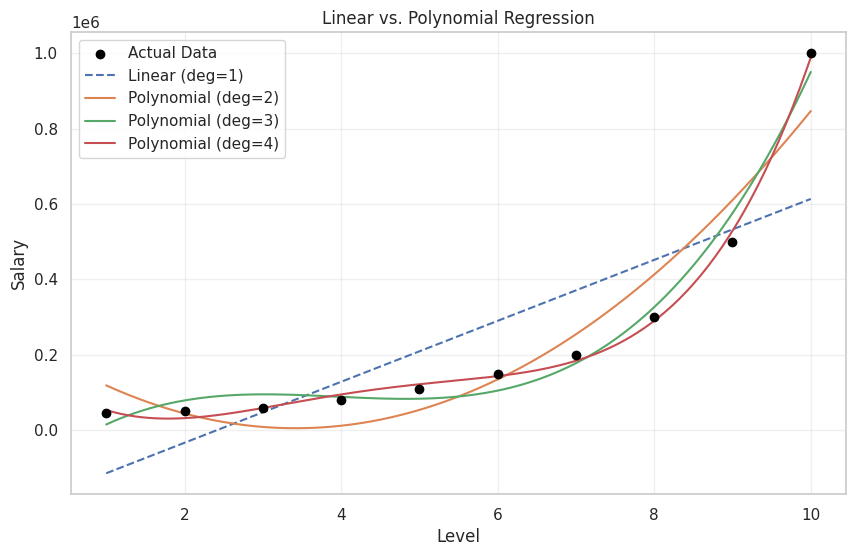

In [56]:
#linear vs polynomial
X = df[["Level"]].values
y = df["Salary"].values

lin_reg = LinearRegression()
lin_reg.fit(X, y)
y_pred_lin = lin_reg.predict(X)

print(f"Linear Regression R^2: {r2_score(y, y_pred_lin):.4f}")
print(f"Linear Regression RMSE: {np.sqrt(mean_squared_error(y, y_pred_lin)):.2f}")

plt.figure(figsize=(10, 6))
plt.scatter(X, y, color="black", label="Actual Data", zorder=5)
X_grid = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)
plt.plot(X_grid, lin_reg.predict(X_grid), "--", label="Linear (deg=1)")

for deg in [2, 3, 4]:
    model = make_pipeline(PolynomialFeatures(degree=deg), LinearRegression())
    model.fit(X, y)
    y_pred = model.predict(X)
    print(f"Degree {deg} -> R^2: {r2_score(y, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y, y_pred)):.2f}")
    plt.plot(X_grid, model.predict(X_grid), label=f"Polynomial (deg={deg})")

plt.title("Linear vs. Polynomial Regression")
plt.xlabel("Level")
plt.ylabel("Salary")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [57]:
# Predict Salary for Level 6.5 using Degree 4 Polynomial Regression
best_model = make_pipeline(PolynomialFeatures(degree=4), LinearRegression())
best_model.fit(X, y)
pred_6_5 = best_model.predict([[6.5]])
print(f"Predicted salary at Level 6.5 (deg=4): {pred_6_5[0]:,.2f}")

Predicted salary at Level 6.5 (deg=4): 158,862.45


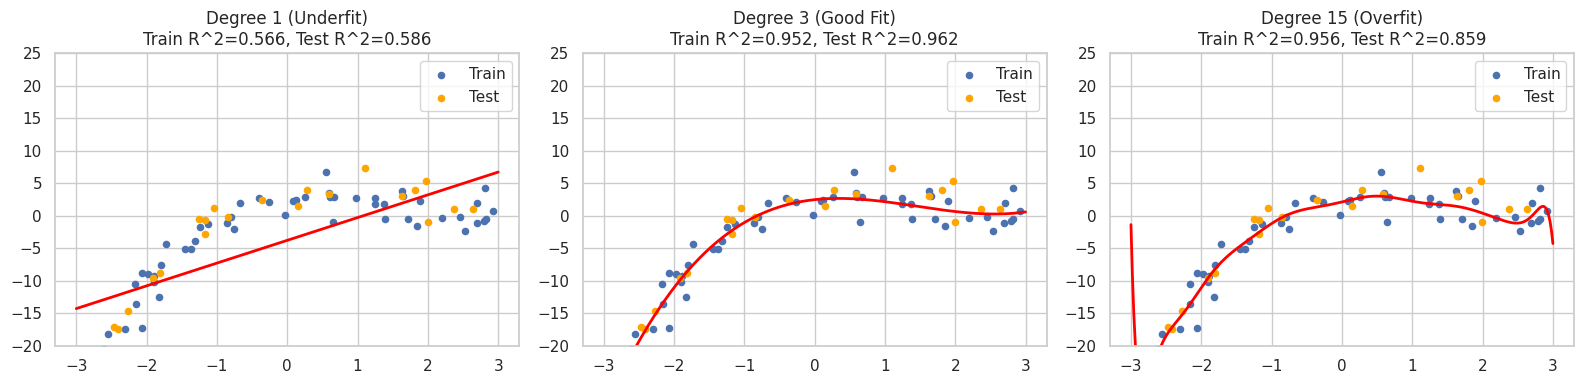

In [58]:
#Underfitting vs. Optimal Fit vs. Overfitting (Train/Test Split)
rng = np.random.RandomState(42)
X_syn = np.sort(rng.uniform(-3, 3, size=80)).reshape(-1, 1)
y_syn = 0.5 * X_syn[:, 0]**3 - 2.0 * X_syn[:, 0]**2 + X_syn[:, 0] + 3.0 + rng.normal(0, 2.0, size=80)

X_train, X_test, y_train, y_test = train_test_split(X_syn, y_syn, test_size=0.3, random_state=42)
X_plot = np.linspace(-3, 3, 300).reshape(-1, 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, deg, title in zip(axes, [1, 3, 15], ["Degree 1 (Underfit)", "Degree 3 (Good Fit)", "Degree 15 (Overfit)"]):
    pipe = make_pipeline(PolynomialFeatures(degree=deg), LinearRegression())
    pipe.fit(X_train, y_train)
    train_r2 = r2_score(y_train, pipe.predict(X_train))
    test_r2 = r2_score(y_test, pipe.predict(X_test))
    ax.scatter(X_train, y_train, s=20, label="Train")
    ax.scatter(X_test, y_test, s=20, color="orange", label="Test")
    ax.plot(X_plot, pipe.predict(X_plot), color="red", linewidth=2)
    ax.set_title(f"{title}\nTrain R^2={train_r2:.3f}, Test R^2={test_r2:.3f}")
    ax.set_ylim(-20, 25)
    ax.legend()

plt.tight_layout()
plt.show()